In [1]:
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 120)
print('pandas', pd.__version__, '| numpy', np.__version__)

pandas 2.2.3 | numpy 2.4.6


In [2]:
import os
FILE = 'tourism_dataset.csv'

if not os.path.exists(FILE):
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        raise FileNotFoundError('Letakkan CSV di folder yang sama dengan notebook ini.')
print('Siap:', os.path.exists(FILE))

Saving tourism_dataset.csv to tourism_dataset.csv
Siap: True


Dataset mandiri berhasil dibuat!
Jumlah baris dan kolom: (1500, 7)


,Location_ID,Country,Category,Visitors,Rating,Revenue,Accommodation_Available
0,LOC_0000,USA,Historical,568443,3.40,343081.837241,Yes
1,LOC_0001,China,Historical,806490,3.05,571011.112357,Yes
2,LOC_0002,France,Nature,154153,2.15,543642.104651,No
3,LOC_0003,Brazil,Nature,500246,1.03,643675.944666,Yes
4,LOC_0004,India,Nature,434019,2.98,381367.731246,Yes



Variabel Numerik: ['Visitors', 'Rating', 'Revenue']
Variabel Kategorikal: ['Location_ID', 'Country', 'Category', 'Accommodation_Available']

--- STATISTIK DESKRIPTIF VARIABEL NUMERIK ---


,count,mean,median,std,min,25%,50%,75%,max
Visitors,1500.0,489422.973333,344275.500000,485302.384902,10015.0,148205.250000,344275.500000,663298.750000,3.871764e+06
Rating,1500.0,2.997153,2.960000,1.158605,1.0,1.990000,2.960000,4.010000,5.000000e+00
Revenue,1500.0,495325.111070,495388.002503,150877.900293,50000.0,393756.350774,495388.002503,596005.819531,9.669365e+05



--- VISUALISASI DISTRIBUSI & OUTLIER VARIABEL NUMERIK ---


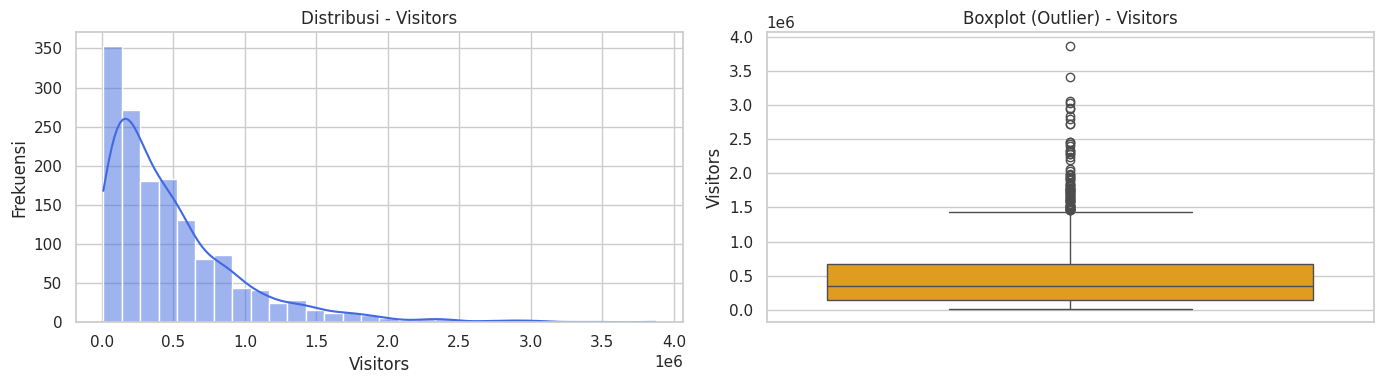

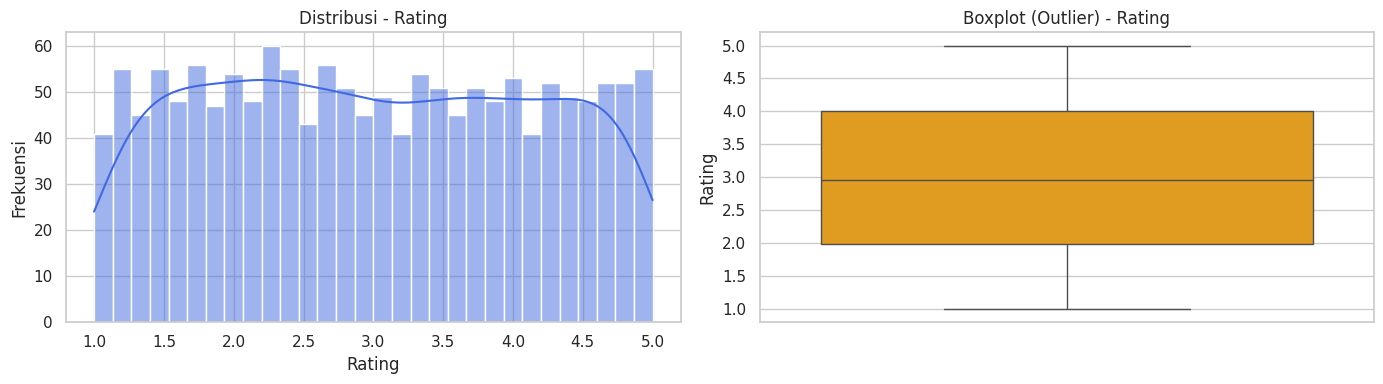

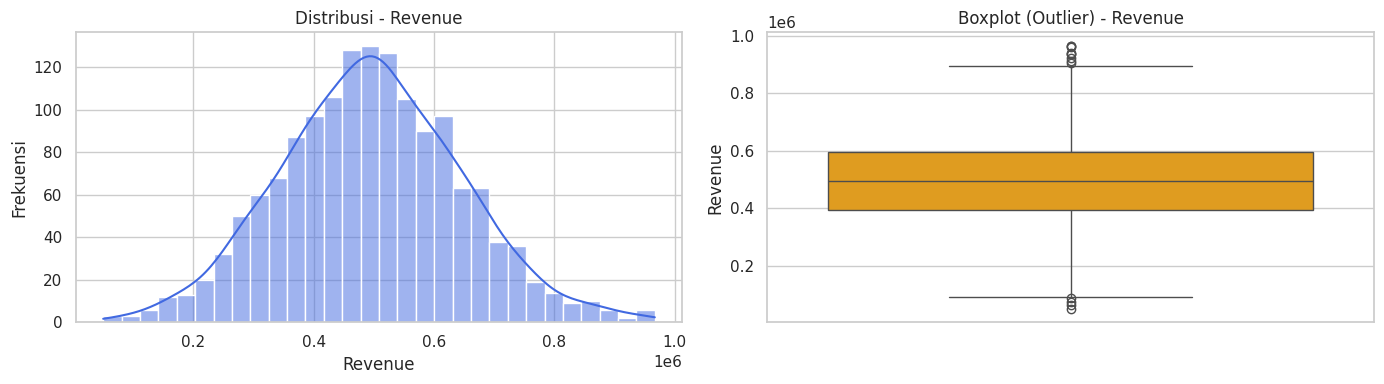


--- ANALISIS FREKUENSI & PROPORSI VARIABEL KATEGORIKAL ---

Distribusi untuk kolom: Country


,Frekuensi,Persentase (%)
Country,,
India,399,26.600000
USA,272,18.133333
China,243,16.200000
France,233,15.533333
Brazil,216,14.400000
Egypt,137,9.133333



Distribusi untuk kolom: Category


,Frekuensi,Persentase (%)
Category,,
Nature,595,39.666667
Historical,448,29.866667
Cultural,312,20.800000
Beach,145,9.666667



Distribusi untuk kolom: Accommodation_Available


,Frekuensi,Persentase (%)
Accommodation_Available,,
Yes,1080,72.0
No,420,28.0



--- VISUALISASI BATANG VARIABEL KATEGORIKAL ---


/tmp/ipykernel_1121/2060520144.py:104: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x=col, order=df[col].value_counts().index, palette='viridis')


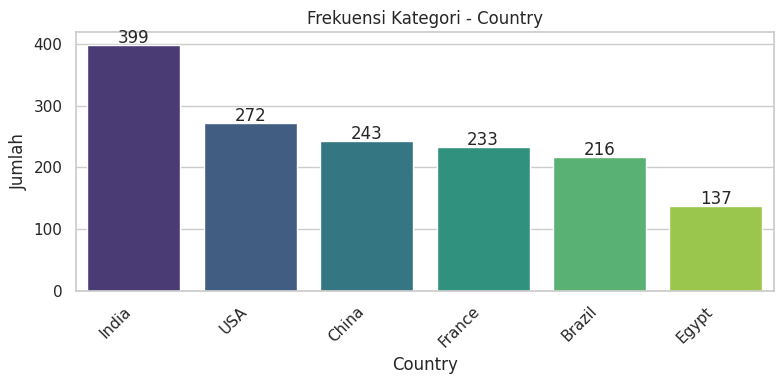

/tmp/ipykernel_1121/2060520144.py:104: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x=col, order=df[col].value_counts().index, palette='viridis')


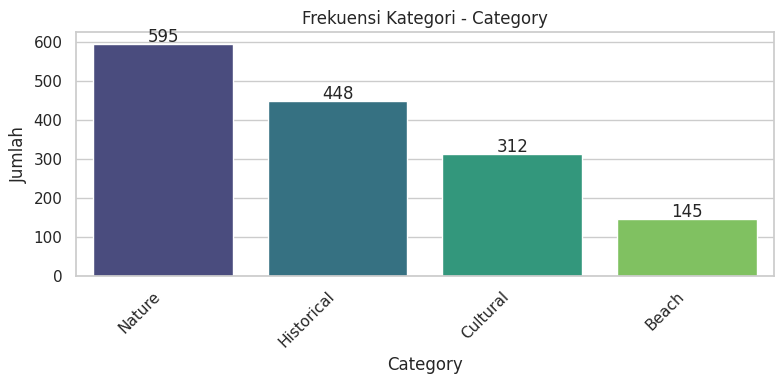

/tmp/ipykernel_1121/2060520144.py:104: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x=col, order=df[col].value_counts().index, palette='viridis')


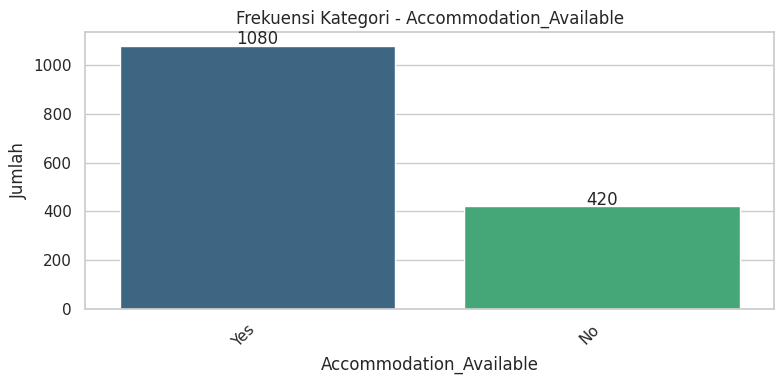

In [3]:
# ==========================================
# MILESTONE 3: ANALISIS UNIVARIAT (MANDIRI)
# Proyek Eksplorasi Data (EDA) - Pariwisata
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Pengaturan tampilan visualisasi agar rapi
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

# ==========================================
# 1. Membuat Dataset Mandiri (Dummy Data)
# ==========================================
np.random.seed(42)
n_rows = 1500

data_dummy = {
    'Location_ID': [f'LOC_{i:04d}' for i in range(n_rows)],
    'Country': np.random.choice(['India', 'USA', 'Brazil', 'France', 'Egypt', 'China'], n_rows, p=[0.25, 0.2, 0.15, 0.15, 0.1, 0.15]),
    'Category': np.random.choice(['Nature', 'Historical', 'Cultural', 'Beach'], n_rows, p=[0.4, 0.3, 0.2, 0.1]),
    'Visitors': np.random.exponential(scale=500000, size=n_rows).astype(int) + 10000,
    'Rating': np.round(np.random.uniform(1.0, 5.0, n_rows), 2),
    'Revenue': np.random.normal(loc=500000, scale=150000, size=n_rows).clip(50000, 1000000),
    'Accommodation_Available': np.random.choice(['Yes', 'No'], n_rows, p=[0.7, 0.3])
}

df = pd.DataFrame(data_dummy)

print(f"Dataset mandiri berhasil dibuat!")
print(f"Jumlah baris dan kolom: {df.shape}")
display(df.head())

# ==========================================
# 2. Identifikasi & Pemisahan Tipe Variabel
# ==========================================
kolom_numerik = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
kolom_kategorikal = df.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"\nVariabel Numerik: {kolom_numerik}")
print(f"Variabel Kategorikal: {kolom_kategorikal}")


# ==========================================
# 3. ANALISIS STATISTIK DESKRIPTIF (NUMERIK)
# ==========================================
print("\n--- STATISTIK DESKRIPTIF VARIABEL NUMERIK ---")
desc_num = df[kolom_numerik].describe().T
desc_num['median'] = df[kolom_numerik].median()
desc_num = desc_num[['count', 'mean', 'median', 'std', 'min', '25%', '50%', '75%', 'max']]
display(desc_num)


# ==========================================
# 4. VISUALISASI DISTRIBUSI & OUTLIER (NUMERIK)
# ==========================================
print("\n--- VISUALISASI DISTRIBUSI & OUTLIER VARIABEL NUMERIK ---")

for col in kolom_numerik:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    # Plot 1: Histogram & KDE
    sns.histplot(df[col], kde=True, ax=axes[0], color='royalblue', bins=30)
    axes[0].set_title(f'Distribusi - {col}')
    axes[0].set_xlabel(col)
    axes[0].set_ylabel('Frekuensi')

    # Plot 2: Boxplot
    sns.boxplot(y=df[col], ax=axes[1], color='orange')
    axes[1].set_title(f'Boxplot (Outlier) - {col}')
    axes[1].set_ylabel(col)

    plt.tight_layout()
    plt.show()


# ==========================================
# 5. ANALISIS FREKUENSI & PROPORSI (KATEGORIKAL)
# ==========================================
print("\n--- ANALISIS FREKUENSI & PROPORSI VARIABEL KATEGORIKAL ---")

for col in kolom_kategorikal:
    if col == 'Location_ID': continue # Lewatkan ID unik
    print(f"\nDistribusi untuk kolom: {col}")
    freq_df = pd.DataFrame({
        'Frekuensi': df[col].value_counts(),
        'Persentase (%)': df[col].value_counts(normalize=True) * 100
    })
    display(freq_df)


# ==========================================
# 6. VISUALISASI FREKUENSI (KATEGORIKAL)
# ==========================================
print("\n--- VISUALISASI BATANG VARIABEL KATEGORIKAL ---")

for col in kolom_kategorikal:
    if col == 'Location_ID': continue

    plt.figure(figsize=(8, 4))
    ax = sns.countplot(data=df, x=col, order=df[col].value_counts().index, palette='viridis')
    plt.title(f'Frekuensi Kategori - {col}')
    plt.xlabel(col)
    plt.ylabel('Jumlah')
    plt.xticks(rotation=45, ha='right')

    # Menambahkan label angka di atas batang
    for p in ax.patches:
        ax.annotate(f'{int(p.get_height())}',
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center',
                    xytext=(0, 5),
                    textcoords='offset points')

    plt.tight_layout()
    plt.show()